In [1]:
from pathlib import Path

import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import issparse
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")
print("Scanpy:", sc.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

All libraries imported successfully!
Scanpy: 1.12.5
NumPy: 2.3.5
Pandas: 3.1.0


/var/folders/_d/g3_c0q8j10ngrt_d18t66p580000gn/T/ipykernel_76644/4148900633.py:12: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


In [2]:
# Project configuration

SEED = 42
N_HVG = 2000
TEST_SIZE = 0.20

MIN_GENES = 200
MIN_CELLS = 3
MAX_GENES_PER_CELL = 2500
MAX_MITO_PERCENT = 5

N_PCS = 30
N_NEIGHBORS = 15

# Project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Project directories
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"

# Create directories if they do not exist
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Output paths
OUTPUT_FILE = DATA_DIR / "pbmc3k_hvg.h5ad"
FIGURE_FILE = FIG_DIR / "day1_pca_umap_baseline.png"

print("Project configuration completed!")
print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Figure directory:", FIG_DIR)


Project configuration completed!
Project root: /Users/gorgeous_jane/scrna-vae-xai
Data directory: /Users/gorgeous_jane/scrna-vae-xai/data
Figure directory: /Users/gorgeous_jane/scrna-vae-xai/figures


In [3]:
# Load the original PBMC 3k dataset

adata = sc.datasets.pbmc3k()

print("PBMC 3k dataset loaded successfully!")
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

PBMC 3k dataset loaded successfully!
Number of cells: 2700
Number of genes: 32738


In [4]:
# Inspect the AnnData object

print(adata)
print("\nCell metadata:")
print(adata.obs.head())

print("\nGene metadata:")
print(adata.var.head())

print("\nExpression matrix type:")
print(type(adata.X))

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

Cell metadata:
Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1]

Gene metadata:
                     gene_ids
index                        
MIR1302-10    ENSG00000243485
FAM138A       ENSG00000237613
OR4F5         ENSG00000186092
RP11-34P13.7  ENSG00000238009
RP11-34P13.8  ENSG00000239945

Expression matrix type:
<class 'scipy.sparse._csr.csr_matrix'>


In [5]:
# Inspect raw gene expression

print("Expression matrix shape:", adata.X.shape)

print("Number of non-zero values:", adata.X.nnz)

total_values = adata.X.shape[0] * adata.X.shape[1]
sparsity = 1 - (adata.X.nnz / total_values)

print(f"Sparsity: {sparsity:.2%}")

print("\nExpression value statistics:")
print("Minimum:", adata.X.min())
print("Maximum:", adata.X.max())
print("Mean:", adata.X.mean())

Expression matrix shape: (2700, 32738)
Number of non-zero values: 2286884
Sparsity: 97.41%

Expression value statistics:
Minimum: 0.0
Maximum: 419.0
Mean: 0.07229826


In [6]:
# Calculate initial quality-control metrics

# Identify mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate QC metrics
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    inplace=True,
    log1p=False
)

# Display summary statistics
print("Cell quality metrics:")
print(
    adata.obs[
        [
            "total_counts",
            "n_genes_by_counts",
            "pct_counts_mt"
        ]
    ].describe()
)

print("\nGene quality metrics:")
print(
    adata.var[
        [
            "n_cells_by_counts",
            "mean_counts",
            "pct_dropout_by_counts"
        ]
    ].describe()
)

Cell quality metrics:
       total_counts  n_genes_by_counts  pct_counts_mt
count   2700.000000        2700.000000    2700.000000
mean    2366.900391         846.994074       2.215132
std     1094.262085         282.104964       1.165438
min      548.000000         212.000000       0.000000
25%     1757.750000         690.000000       1.536238
50%     2197.000000         817.000000       2.029639
75%     2763.000000         953.250000       2.640218
max    15844.000000        3422.000000      22.569027

Gene quality metrics:
       n_cells_by_counts   mean_counts  pct_dropout_by_counts
count       32738.000000  32738.000000           32738.000000
mean           69.854114      0.072298              97.412811
std           238.263898      0.852401               8.824589
min             0.000000      0.000000               0.000000
25%             0.000000      0.000000              98.703704
50%             1.000000      0.000370              99.962963
75%            35.000000      0.013

In [7]:
# Step 1: Record initial dataset size
initial_cells = adata.n_obs
initial_genes = adata.n_vars

# Step 2: Remove cells expressing fewer than 200 genes
sc.pp.filter_cells(adata, min_genes=MIN_GENES)

cells_after_gene_filter = adata.n_obs

# Step 3: Remove genes detected in fewer than 3 cells
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)

genes_after_filter = adata.n_vars

# Step 4: Remove cells with excessive gene counts
# or mitochondrial percentage
keep_cells = (
    (adata.obs["n_genes_by_counts"] < MAX_GENES_PER_CELL)
    &
    (adata.obs["pct_counts_mt"] < MAX_MITO_PERCENT)
)

adata = adata[keep_cells].copy()

# Step 5: Report filtering results
print("QUALITY CONTROL SUMMARY")
print("------------------------------")
print(f"Initial cells: {initial_cells}")
print(f"Cells after minimum gene filter: {cells_after_gene_filter}")
print(f"Cells after final QC: {adata.n_obs}")
print(f"Cells removed: {initial_cells - adata.n_obs}")
print()
print(f"Initial genes: {initial_genes}")
print(f"Genes after filtering: {genes_after_filter}")
print("------------------------------")

QUALITY CONTROL SUMMARY
------------------------------
Initial cells: 2700
Cells after minimum gene filter: 2700
Cells after final QC: 2638
Cells removed: 62

Initial genes: 32738
Genes after filtering: 13714
------------------------------


In [8]:
# Preserve the original raw counts
adata.layers["counts"] = adata.X.copy()

print("Raw counts successfully preserved.")
print("Counts layer shape:", adata.layers["counts"].shape)
print("Expression matrix shape:", adata.X.shape)

Raw counts successfully preserved.
Counts layer shape: (2638, 13714)
Expression matrix shape: (2638, 13714)


In [9]:
# Normalise each cell to 10,000 total counts
sc.pp.normalize_total(adata, target_sum=1e4)

# Apply log1p transformation
sc.pp.log1p(adata)

print("Normalisation and log transformation completed.")
print("Expression matrix shape:", adata.X.shape)
print("Minimum expression value:", adata.X.min())
print("Maximum expression value:", adata.X.max())

Normalisation and log transformation completed.
Expression matrix shape: (2638, 13714)
Minimum expression value: 0.0
Maximum expression value: 7.4695992


In [10]:
# Preserve all genes and their log-normalised expression values
adata.raw = adata.copy()

print("Full gene expression data preserved in adata.raw.")
print("Current dataset shape:", adata.shape)
print("Preserved full dataset shape:", adata.raw.shape)

Full gene expression data preserved in adata.raw.
Current dataset shape: (2638, 13714)
Preserved full dataset shape: (2638, 13714)


In [11]:
# Identify the 2,000 most highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=N_HVG,
    flavor="seurat"
)

# Count selected genes
n_hvg = adata.var["highly_variable"].sum()

print("Highly variable gene selection completed.")
print("Total genes:", adata.n_vars)
print("Highly variable genes selected:", n_hvg)

# Inspect the top selected genes
print("\nTop highly variable genes:")
print(
    adata.var.loc[
        adata.var["highly_variable"],
        ["means", "dispersions", "dispersions_norm"]
    ].head(10)
)

Highly variable gene selection completed.
Total genes: 13714
Highly variable genes selected: 2000

Top highly variable genes:
             means  dispersions  dispersions_norm
index                                            
TNFRSF4   0.277410     2.086050          0.665406
CPSF3L    0.385194     4.506987          2.955005
ATAD3C    0.038252     3.953486          4.352607
C1orf86   0.678283     2.713522          0.543183
RER1      0.814813     3.447533          1.582528
TNFRSF25  0.302615     3.195535          1.274278
TNFRSF9   0.032145     2.691045          1.859952
CA6       0.009766     2.004851          0.505081
CTNNBIP1  0.307042     4.213911          2.579405
SRM       0.522884     2.764689          0.722116


In [12]:
# Keep only the highly variable genes
adata = adata[:, adata.var["highly_variable"]].copy()

print("HVG subsetting completed.")
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Working matrix shape:", adata.X.shape)
print("Preserved full gene matrix:", adata.raw.shape)

HVG subsetting completed.
Cells: 2638
Genes: 2000
Working matrix shape: (2638, 2000)
Preserved full gene matrix: (2638, 13714)


In [13]:
# Check the working expression matrix
X = adata.X

print("DATA INTEGRITY CHECK")
print("------------------------------")
print("Matrix shape:", X.shape)
print("Contains NaN:", np.isnan(X.data).any())
print("Contains infinite values:", np.isinf(X.data).any())
print("Minimum expression:", X.min())
print("Maximum expression:", X.max())
print("Number of selected genes:", adata.var_names.nunique())
print("------------------------------")

DATA INTEGRITY CHECK
------------------------------
Matrix shape: (2638, 2000)
Contains NaN: False
Contains infinite values: False
Minimum expression: 0.0
Maximum expression: 7.4695992
Number of selected genes: 2000
------------------------------


In [15]:
# Load the processed PBMC reference dataset
reference = sc.datasets.pbmc3k_processed()

print("Reference dataset loaded.")
print("Reference shape:", reference.shape)

print("\nAvailable cell annotations:")
print(reference.obs.columns.tolist())

print("\nReference cluster counts:")
print(reference.obs["louvain"].value_counts().sort_index())

  0%|          | 0.00/23.5M [00:00<?, ?B/s]

Reference dataset loaded.
Reference shape: (2638, 1838)

Available cell annotations:
['n_genes', 'percent_mito', 'n_counts', 'louvain']

Reference cluster counts:
louvain
CD4 T cells          1144
CD14+ Monocytes       480
B cells               342
CD8 T cells           316
NK cells              154
FCGR3A+ Monocytes     150
Dendritic cells        37
Megakaryocytes         15
Name: count, dtype: int64


In [16]:
# Match reference annotations to the working dataset by cell barcode
reference_labels = reference.obs["louvain"].reindex(adata.obs_names)

print("CELL BARCODE ALIGNMENT CHECK")
print("------------------------------")
print("Cells in working dataset:", adata.n_obs)
print("Matching reference annotations:", reference_labels.notna().sum())
print("Missing annotations:", reference_labels.isna().sum())
print("------------------------------")

CELL BARCODE ALIGNMENT CHECK
------------------------------
Cells in working dataset: 2638
Matching reference annotations: 2638
Missing annotations: 0
------------------------------


In [17]:
# Transfer reference annotations to the working dataset
adata.obs["louvain_cluster"] = pd.Categorical(
    reference_labels,
    categories=reference.obs["louvain"].cat.categories
)

print("Reference annotations successfully transferred.")
print("\nCluster counts in working dataset:")
print(adata.obs["louvain_cluster"].value_counts())

Reference annotations successfully transferred.

Cluster counts in working dataset:
louvain_cluster
CD4 T cells          1144
CD14+ Monocytes       480
B cells               342
CD8 T cells           316
NK cells              154
FCGR3A+ Monocytes     150
Dendritic cells        37
Megakaryocytes         15
Name: count, dtype: int64


In [18]:
# Create cell indices
cell_indices = np.arange(adata.n_obs)

# Split cells while preserving cluster proportions
train_indices, test_indices = train_test_split(
    cell_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=adata.obs["louvain_cluster"]
)

print("TRAIN/TEST SPLIT")
print("------------------------------")
print("Total cells:", len(cell_indices))
print("Training cells:", len(train_indices))
print("Testing cells:", len(test_indices))
print("Training proportion:", len(train_indices) / len(cell_indices))
print("Testing proportion:", len(test_indices) / len(cell_indices))
print("------------------------------")

TRAIN/TEST SPLIT
------------------------------
Total cells: 2638
Training cells: 2110
Testing cells: 528
Training proportion: 0.7998483699772555
Testing proportion: 0.2001516300227445
------------------------------


In [19]:
# Extract cluster labels for each split
train_labels = adata.obs.iloc[train_indices]["louvain_cluster"]
test_labels = adata.obs.iloc[test_indices]["louvain_cluster"]

# Compare cluster proportions
cluster_comparison = pd.DataFrame({
    "Full dataset (%)": adata.obs["louvain_cluster"].value_counts(normalize=True) * 100,
    "Training (%)": train_labels.value_counts(normalize=True) * 100,
    "Testing (%)": test_labels.value_counts(normalize=True) * 100
}).fillna(0)

print("CLUSTER PROPORTION CHECK")
print(cluster_comparison.round(2))

CLUSTER PROPORTION CHECK
                   Full dataset (%)  Training (%)  Testing (%)
louvain_cluster                                               
CD4 T cells                   43.37         43.36        43.37
CD14+ Monocytes               18.20         18.20        18.18
B cells                       12.96         12.94        13.07
CD8 T cells                   11.98         11.99        11.93
NK cells                       5.84          5.83         5.87
FCGR3A+ Monocytes              5.69          5.69         5.68
Dendritic cells                1.40          1.42         1.33
Megakaryocytes                 0.57          0.57         0.57


In [20]:
# Convert the normalised HVG matrix to dense float32
X = adata.X.toarray().astype(np.float32)

# Extract training and testing data
X_train = X[train_indices]
X_test = X[test_indices]

print("VAE INPUT PREPARATION")
print("------------------------------")
print("Full matrix:", X.shape)
print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)
print("Data type:", X.dtype)
print("Contains NaN:", np.isnan(X).any())
print("Contains infinite values:", np.isinf(X).any())
print("------------------------------")

VAE INPUT PREPARATION
------------------------------
Full matrix: (2638, 2000)
Training matrix: (2110, 2000)
Testing matrix: (528, 2000)
Data type: float32
Contains NaN: False
Contains infinite values: False
------------------------------


In [21]:
# Check whether key immune-cell markers are among the HVGs

marker_genes = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D"
]

marker_check = pd.DataFrame({
    "Gene": marker_genes,
    "Present in 2000 HVGs": [
        gene in adata.var_names for gene in marker_genes
    ],
    "Present in full dataset": [
        gene in adata.raw.var_names for gene in marker_genes
    ]
})

print("IMMUNE MARKER GENE CHECK")
print("------------------------------")
print(marker_check.to_string(index=False))
print("------------------------------")

IMMUNE MARKER GENE CHECK
------------------------------
 Gene  Present in 2000 HVGs  Present in full dataset
CD79A                  True                     True
MS4A1                  True                     True
 NKG7                  True                     True
 GNLY                  True                     True
  LYZ                  True                     True
 CST3                  True                     True
 CD3D                 False                     True
------------------------------


In [22]:
# Create a separate copy for baseline dimensionality reduction
baseline = adata.copy()

# Scale expression values for PCA
sc.pp.scale(baseline, max_value=10)

# Calculate PCA
sc.tl.pca(
    baseline,
    n_comps=N_PCS,
    random_state=SEED
)

# Calculate neighbourhood graph
sc.pp.neighbors(
    baseline,
    n_neighbors=N_NEIGHBORS,
    n_pcs=N_PCS,
    random_state=SEED
)

# Calculate UMAP
sc.tl.umap(
    baseline,
    random_state=SEED
)

print("PCA and UMAP calculations completed.")
print("PCA shape:", baseline.obsm["X_pca"].shape)
print("UMAP shape:", baseline.obsm["X_umap"].shape)

/usr/local/Cellar/python@3.12/3.12.16/Frameworks/Python.framework/Versions/3.12/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


PCA and UMAP calculations completed.
PCA shape: (2638, 30)
UMAP shape: (2638, 2)


In [23]:
print("PCA calculated:", "X_pca" in baseline.obsm)
print("UMAP calculated:", "X_umap" in baseline.obsm)

if "X_pca" in baseline.obsm:
    print("PCA shape:", baseline.obsm["X_pca"].shape)

if "X_umap" in baseline.obsm:
    print("UMAP shape:", baseline.obsm["X_umap"].shape)

PCA calculated: True
UMAP calculated: True
PCA shape: (2638, 30)
UMAP shape: (2638, 2)


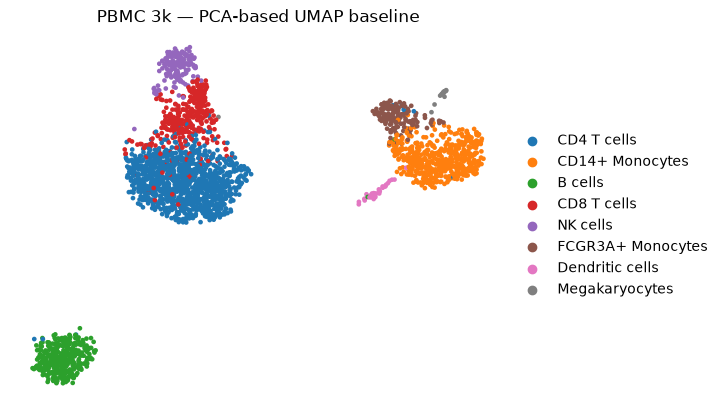

In [24]:
sc.pl.umap(
    baseline,
    color="louvain_cluster",
    title="PBMC 3k — PCA-based UMAP baseline",
    legend_loc="right margin",
    frameon=False,
    show=True
)

In [25]:
t_markers = ["CD3E", "CD3G", "CD2", "IL7R", "LTB", "CCR7", "CD8A"]
print({g: g in adata.var_names for g in t_markers})

{'CD3E': False, 'CD3G': False, 'CD2': True, 'IL7R': False, 'LTB': True, 'CCR7': False, 'CD8A': False}


In [26]:
# Pre-declared T-cell marker panel
PANEL = ["CD3D", "CD3E", "CD3G", "IL7R", "CD8A", "CCR7"]

# Identify panel genes available after QC
available_panel = [
    gene for gene in PANEL
    if gene in adata.raw.var_names
]

missing_panel = [
    gene for gene in PANEL
    if gene not in adata.raw.var_names
]

# Reconstruct the 2,000-HVG baseline
hvg = adata.copy()

# Reconstruct the full normalised dataset
full = adata.raw.to_adata()

# Retain HVGs plus available pre-declared panel genes
keep_genes = (
    full.var_names.isin(adata.var_names)
    | full.var_names.isin(available_panel)
)

panel = full[:, keep_genes].copy()

# Preserve the original reference annotations
panel.obs["louvain_cluster"] = adata.obs[
    "louvain_cluster"
].copy()

# Reuse the exact existing stratified split
split_labels = np.full(adata.n_obs, "train", dtype=object)
split_labels[test_indices] = "test"

hvg.obs["split"] = split_labels
panel.obs["split"] = split_labels

# Keep both expression matrices as sparse float32
hvg.X = hvg.X.astype(np.float32)
panel.X = panel.X.astype(np.float32)

# Save both datasets
baseline_file = DATA_DIR / "pbmc3k_hvg.h5ad"
panel_file = DATA_DIR / "pbmc3k_hvg_panel.h5ad"

hvg.write_h5ad(baseline_file)
panel.write_h5ad(panel_file)

print("DATASET CREATION COMPLETED")
print("------------------------------")
print("HVG baseline:", hvg.shape)
print("Panel dataset:", panel.shape)
print("Training cells:", sum(split_labels == "train"))
print("Testing cells:", sum(split_labels == "test"))
print("Panel genes available:", available_panel)
print("Panel genes missing:", missing_panel)
print("Baseline saved:", baseline_file.exists())
print("Panel dataset saved:", panel_file.exists())
print("------------------------------")

DATASET CREATION COMPLETED
------------------------------
HVG baseline: (2638, 2000)
Panel dataset: (2638, 2006)
Training cells: 2110
Testing cells: 528
Panel genes available: ['CD3D', 'CD3E', 'CD3G', 'IL7R', 'CD8A', 'CCR7']
Panel genes missing: []
Baseline saved: True
Panel dataset saved: True
------------------------------


In [27]:
# Check all seven biological validation markers
marker_genes = [
    "CD79A", "MS4A1",
    "NKG7", "GNLY",
    "LYZ", "CST3",
    "CD3D"
]

marker_check_panel = pd.DataFrame({
    "Gene": marker_genes,
    "Present in panel dataset": [
        gene in panel.var_names for gene in marker_genes
    ]
})

print("PANEL DATASET MARKER CHECK")
print("------------------------------")
print(marker_check_panel.to_string(index=False))
print("------------------------------")
print("Total markers present:",
      marker_check_panel["Present in panel dataset"].sum(),
      "of", len(marker_genes))

PANEL DATASET MARKER CHECK
------------------------------
 Gene  Present in panel dataset
CD79A                      True
MS4A1                      True
 NKG7                      True
 GNLY                      True
  LYZ                      True
 CST3                      True
 CD3D                      True
------------------------------
Total markers present: 7 of 7


In [28]:
import gc

# Release old dense arrays and the previous PCA baseline
del X, X_train, X_test, baseline
gc.collect()

# Create PCA/UMAP baseline from the 2,006-gene panel
baseline = panel.copy()

# Scale for PCA
sc.pp.scale(baseline, max_value=10)

# Calculate PCA
sc.tl.pca(
    baseline,
    n_comps=N_PCS,
    random_state=SEED
)

# Calculate neighbourhood graph
sc.pp.neighbors(
    baseline,
    n_neighbors=N_NEIGHBORS,
    n_pcs=N_PCS,
    random_state=SEED
)

# Calculate UMAP
sc.tl.umap(
    baseline,
    random_state=SEED
)

print("PANEL PCA/UMAP COMPLETED")
print("------------------------------")
print("Input genes:", baseline.n_vars)
print("PCA shape:", baseline.obsm["X_pca"].shape)
print("UMAP shape:", baseline.obsm["X_umap"].shape)
print("------------------------------")

/usr/local/Cellar/python@3.12/3.12.16/Frameworks/Python.framework/Versions/3.12/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


PANEL PCA/UMAP COMPLETED
------------------------------
Input genes: 2006
PCA shape: (2638, 30)
UMAP shape: (2638, 2)
------------------------------


In [29]:
# Save the final PCA-based UMAP figure
PANEL_FIGURE_FILE = FIG_DIR / "day1_pca_umap_panel.png"

sc.pl.umap(
    baseline,
    color="louvain_cluster",
    title="PBMC 3k — PCA-based UMAP (2,006-gene panel)",
    legend_loc="right margin",
    frameon=False,
    show=False
)

plt.savefig(
    PANEL_FIGURE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Figure saved:", PANEL_FIGURE_FILE)
print("File exists:", PANEL_FIGURE_FILE.exists())

Figure saved: /Users/gorgeous_jane/scrna-vae-xai/figures/day1_pca_umap_panel.png
File exists: True
